# Análisis exploratorio — GOOGL diario (2009-2018)

Dataset: `STOCKS_GOOGL` de `gym-anytrading` (copia en `data/STOCKS_GOOGL.csv`). Objetivo: entender
las características de los datos que afectan al agente y justificar el estado y la recompensa.

Períodos (`rl_games_sb.data.SPLITS`): **train** 2009-05 → 2015-12, **val** 2016, **test (held-out)** 2017-01 → 2018-08.
El período de test se muestra aquí solo de forma descriptiva (precio y régimen); ninguna decisión
de diseño usa sus estadísticos.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from rl_games_sb import data

df = data.load()
close = df["Close"]
ret = np.log(close).diff().dropna()
period = pd.Series("train", index=df.index)
for name, (start, end) in data.SPLITS.items():
    period[start:end] = name

C = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ae",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlelocation": "left",
    "axes.titlesize": 11, "figure.dpi": 110,
})

def shade(ax):
    for name, (start, end) in data.SPLITS.items():
        start = max(pd.Timestamp(start), df.index[0])
        ax.axvspan(start, min(pd.Timestamp(end), df.index[-1]), color=C[name], alpha=0.07)
        ax.text(start, 1.0, f" {name}", transform=ax.get_xaxis_transform(),
                va="top", fontsize=8, color=MUTED)
df.shape, df.index.min().date(), df.index.max().date()

((2335, 6), datetime.date(2009, 5, 22), datetime.date(2018, 8, 29))

## 1. Resumen por período

In [2]:
def summary(r, c):
    value = c / c.iloc[0]
    return pd.Series({
        "días": len(r), "retorno acumulado": c.iloc[-1] / c.iloc[0] - 1,
        "retorno anual": np.exp(r.mean() * 252) - 1, "volatilidad anual": r.std() * np.sqrt(252),
        "máx. drawdown": (value / value.cummax() - 1).min(),
        "% días al alza": (r > 0).mean(), "asimetría": r.skew(), "curtosis (exceso)": r.kurt(),
    })

table = pd.DataFrame({
    name: summary(ret[start:end], close[start:end]) for name, (start, end) in data.SPLITS.items()
})
table.round(3)

,train,val,test
días,1664.000,252.000,418.000
retorno acumulado,2.950,0.043,0.565
retorno anual,0.231,0.019,0.326
volatilidad anual,0.249,0.202,0.202
máx. drawdown,-0.304,-0.135,-0.154
% días al alza,0.521,0.512,0.553
asimetría,0.843,-0.627,-0.731
curtosis (exceso),13.292,2.451,3.012


**Lectura.** Train es fuertemente alcista (×3,9; +23 % anual) y validación es casi plana (+4 %, con
una caída de 13 %). Comprar y mantener es un baseline exigente: un agente que aprenda "estar
invertido casi siempre" ya es razonable; para superarlo tendría que evitar caídas sin perder los
días de subida, y cada salida y entrada cuesta 10 bps. Las colas de train son mucho más pesadas
(curtosis 13) que las de val.

## 2. Panorama: por qué este problema es difícil

Una sola figura con las tres caras del problema: la **tendencia** (panel superior), las **caídas**
(drawdown, panel central) y los **regímenes de riesgo** (volatilidad, panel inferior). Los
triángulos marcan los 8 movimientos diarios más grandes del período: **todos son días de
publicación de resultados trimestrales** de Google, información que no está en el precio.

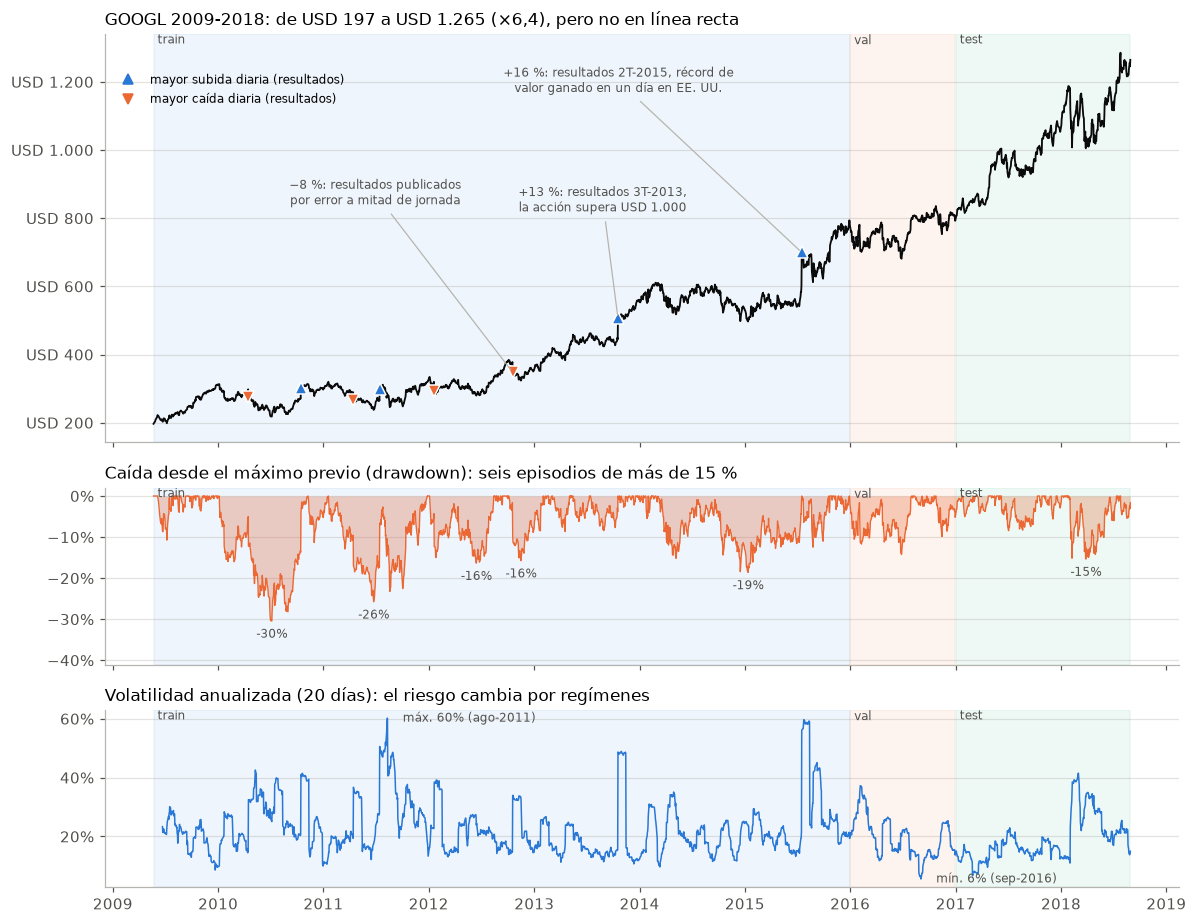

In [3]:
import matplotlib.dates as mdates

MONTHS = "ene feb mar abr may jun jul ago sep oct nov dic".split()
usd = lambda x, _=None: "USD " + f"{x:,.0f}".replace(",", ".")

EVENTS = {  # verified with press coverage of each day; (text, label offset in points)
    "2012-10-18": ("−8 %: resultados publicados\npor error a mitad de jornada", (-90, 110)),
    "2013-10-18": ("+13 %: resultados 3T-2013,\nla acción supera USD 1.000", (-10, 70)),
    "2015-07-17": ("+16 %: resultados 2T-2015, récord de\nvalor ganado en un día en EE. UU.", (-120, 105)),
}
dd = close / close.cummax() - 1
vol = ret.rolling(20).std() * np.sqrt(252)
extremes = ret.abs().nlargest(8).index

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True,
                                    gridspec_kw={"height_ratios": [3, 1.3, 1.3]})
ax1.plot(close.index, close, color=INK, linewidth=1.2)
for d in extremes:
    up = ret[d] > 0
    ax1.plot(d, close[d], marker="^" if up else "v", markersize=8, linestyle="none",
             color=C["train"] if up else C["val"], markeredgecolor="white", markeredgewidth=1)
for d, (text, offset) in EVENTS.items():
    d = pd.Timestamp(d)
    ax1.annotate(text, (d, close[d]), xytext=offset,
                 textcoords="offset points", ha="center", fontsize=8, color=MUTED,
                 arrowprops=dict(arrowstyle="-", color="#b5b4ae", linewidth=0.8))
ax1.plot([], [], "^", color=C["train"], label="mayor subida diaria (resultados)")
ax1.plot([], [], "v", color=C["val"], label="mayor caída diaria (resultados)")
ax1.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(0, 0.93))
ax1.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(usd))
growth = f"{close.iloc[-1] / close.iloc[0]:.1f}".replace(".", ",")
ax1.set_title(f"GOOGL {close.index[0].year}-{close.index[-1].year}: de {usd(close.iloc[0])} a "
              f"{usd(close.iloc[-1])} (×{growth}), pero no en línea recta")

ax2.fill_between(dd.index, dd, 0, color=C["val"], alpha=0.3, linewidth=0)
ax2.plot(dd.index, dd, color=C["val"], linewidth=0.9)
for start, end in [("2010", "2010"), ("2011", "2011"), ("2012-01", "2012-08"),
                   ("2012-10", "2013-01"), ("2014-03", "2015-07"), ("2018", "2018")]:
    trough = dd[start:end].idxmin()
    ax2.annotate(f"{dd[trough]:.0%}", (trough, dd[trough]), xytext=(0, -11),
                 textcoords="offset points", ha="center", fontsize=8, color=MUTED)
ax2.set_ylim(dd.min() * 1.35, 0.02)
ax2.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax2.set_title("Caída desde el máximo previo (drawdown): seis episodios de más de 15 %")

ax3.plot(vol.index, vol, color=C["train"], linewidth=1)
for d, label in [(vol.idxmax(), "máx."), (vol.idxmin(), "mín.")]:
    ax3.annotate(f"{label} {vol[d]:.0%} ({MONTHS[d.month - 1]}-{d.year})", (d, vol[d]),
                 xytext=(10, 0), textcoords="offset points", fontsize=8, color=MUTED, va="center")
ax3.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax3.set_title("Volatilidad anualizada (20 días): el riesgo cambia por regímenes")
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

for ax in (ax1, ax2, ax3):
    shade(ax)
fig.tight_layout()
out = data.DATA_PATH.parents[1] / "results" / "eda"
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "googl_contexto.png", dpi=150)

**Lectura.**
- **Tendencia:** ×6,4 en nueve años. Comprar y mantener es un rival muy difícil: cualquier día
  fuera del mercado arriesga perderse parte de esa subida.
- **Caídas:** seis episodios de más de 15 %, el peor de −30 % (2010). Cada episodio duró de 4 a
  17 meses desde el máximo hasta recuperarlo. Una estrategia que salga en una caída debe volver a entrar a tiempo.
- **Regímenes:** la volatilidad va de 6 % a 60 % anual. El riesgo de estar invertido no es
  constante, y 2016 (validación) es mucho más tranquilo que el entrenamiento: **no estacionariedad**.
- **Saltos por información externa:** los 8 mayores movimientos diarios (entre −8 % y +16 %) son días
  de resultados trimestrales. Uno incluso fue un error operativo (resultados publicados antes de
  tiempo). El agente solo ve indicadores de precio, así que estos saltos son **impredecibles para
  él**, y pesan mucho en el resultado final.
- **Escala:** el precio cambia un orden de magnitud. Por eso el estado usa retornos y razones
  (precio / media móvil), no precios crudos como `stocks-v0`.

## 3. Distribución de los retornos diarios

media diaria 0.0826%  std 1.571%  días |r| > 3 std: 19


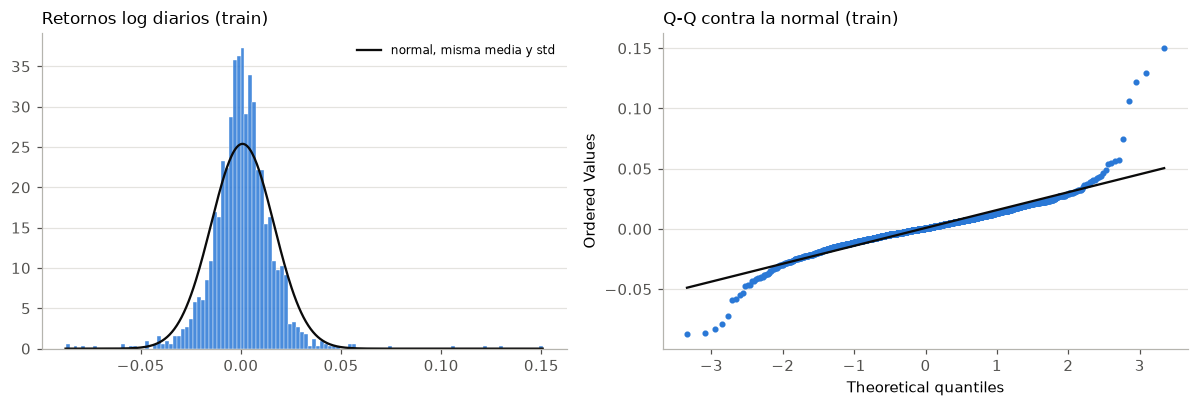

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
r = ret[: data.SPLITS["train"][1]]
axes[0].hist(r, bins=120, density=True, color=C["train"], alpha=0.85, edgecolor="white", linewidth=0.3)
x = np.linspace(r.min(), r.max(), 400)
axes[0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), color=INK, linewidth=1.5, label="normal, misma media y std")
axes[0].set_title("Retornos log diarios (train)")
axes[0].legend(frameon=False, fontsize=8)
stats.probplot(r, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(color=C["train"], markersize=3)
axes[1].get_lines()[1].set(color=INK)
axes[1].set_title("Q-Q contra la normal (train)")
fig.tight_layout()
print(f"media diaria {r.mean():.4%}  std {r.std():.3%}  días |r| > 3 std: {(r.abs() > 3 * r.std()).sum()}")

**Lectura.** La media diaria es diminuta frente a la desviación estándar (relación señal/ruido
muy baja), y las colas son pesadas: hay pocos días extremos que
dominan el resultado (el mayor: +16 % el 17-jul-2015, tras resultados trimestrales). Consecuencias: (a) la recompensa diaria es muy ruidosa, lo que exige varias
semillas y episodios largos; (b) estar fuera del mercado en uno de esos días cuesta mucho.

## 4. Períodos de alta y baja volatilidad

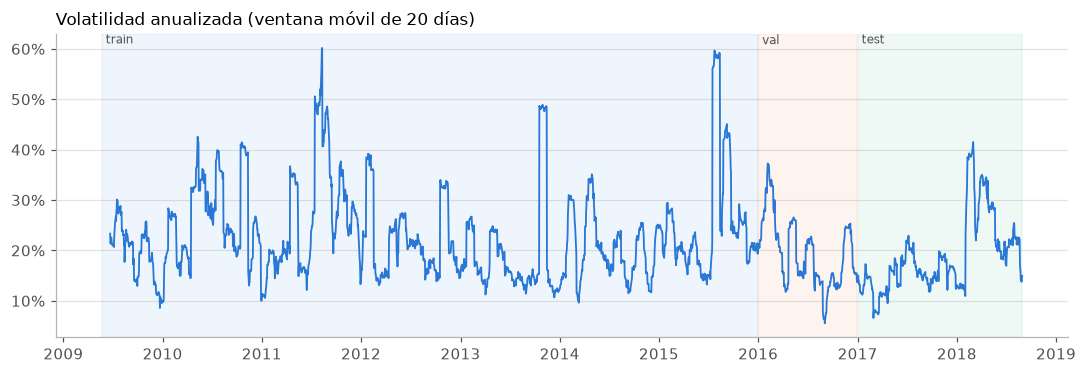

In [5]:
vol = ret.rolling(20).std() * np.sqrt(252)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(vol.index, vol, color=C["train"], linewidth=1.2)
shade(ax)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Volatilidad anualizada (ventana móvil de 20 días)")
fig.tight_layout()

**Lectura.** La volatilidad se agrupa en regímenes (clustering): episodios de 30-50 % anual
alternan con meses tranquilos cerca de 15-20 %. Esto justifica incluir `vol_20` en el estado: el
riesgo de estar invertido no es constante en el tiempo.

## 5. Tendencias y caídas (drawdown de comprar y mantener)

test    -0.153575
train   -0.304236
val     -0.142098
Name: Close, dtype: float64

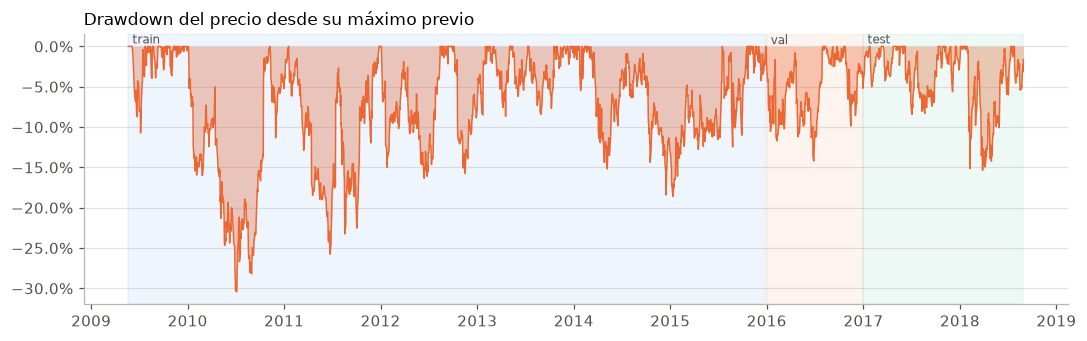

In [6]:
dd = close / close.cummax() - 1
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.fill_between(dd.index, dd, 0, color=C["val"], alpha=0.35, linewidth=0)
ax.plot(dd.index, dd, color=C["val"], linewidth=1)
shade(ax)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Drawdown del precio desde su máximo previo")
fig.tight_layout()
worst = dd.groupby(period).min()
worst

**Lectura.** Las caídas de 20-30 % existen pero se recuperan en meses: una estrategia que
salga del mercado en una caída necesita volver a entrar a tiempo, o se pierde la recuperación.
La recompensa R2 (penalización por drawdown) busca precisamente reducir estas caídas.

## 6. Volumen

correlación |retorno| vs volume_z (train): 0.517


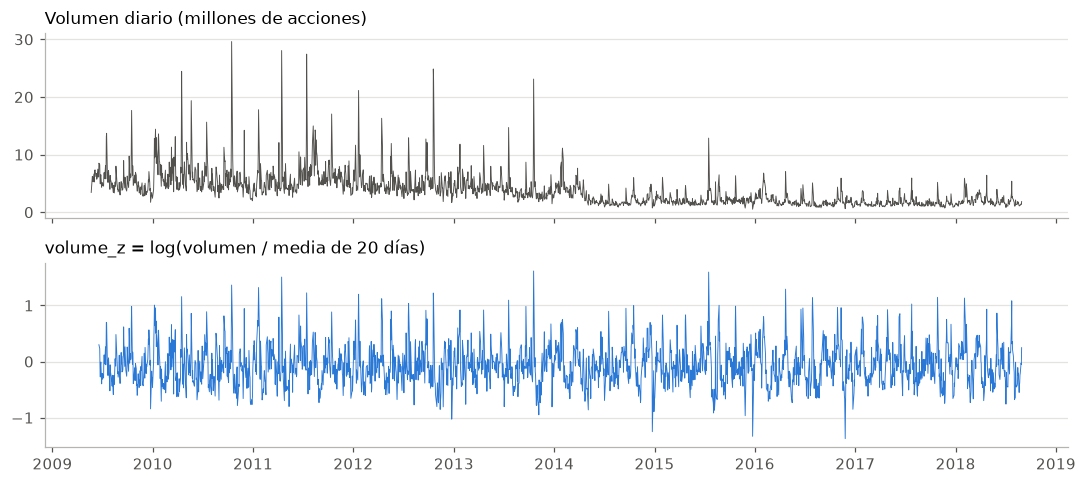

In [7]:
vz = np.log(df["Volume"] / df["Volume"].rolling(20).mean())
fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
axes[0].plot(df.index, df["Volume"] / 1e6, color=MUTED, linewidth=0.6)
axes[0].set_title("Volumen diario (millones de acciones)")
axes[1].plot(vz.index, vz, color=C["train"], linewidth=0.6)
axes[1].set_title("volume_z = log(volumen / media de 20 días)")
fig.tight_layout()
both = pd.concat([ret.abs(), vz], axis=1, join="inner").loc[:"2015"]
print(f"correlación |retorno| vs volume_z (train): {both.corr().iloc[0, 1]:.3f}")

**Lectura.** El volumen crudo cambia de nivel en abril de 2014 (con la creación de las acciones
clase C, la mediana diaria de GOOGL pasa de 4,7 M a 1,7 M), lo que lo hace inutilizable sin normalizar; la versión relativa a su media de 20 días es estacionaria y se
correlaciona con la magnitud de los movimientos (días de noticias).

## 7. Comportamiento de los indicadores del estado

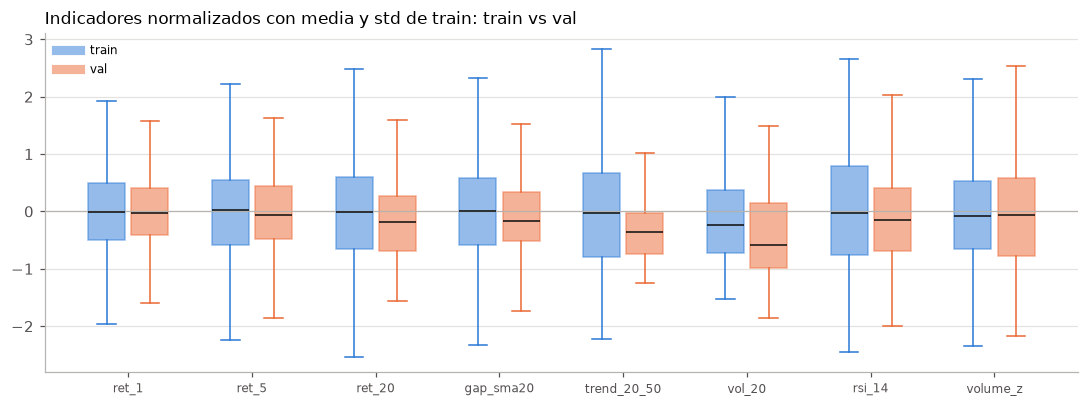

In [8]:
feats = data.features(df)
_, train_z = data.split("train", df)
_, val_z = data.split("val", df)
fig, ax = plt.subplots(figsize=(10, 3.8))
pos = np.arange(len(data.FEATURES))
for k, (name, z) in enumerate([("train", train_z), ("val", val_z)]):
    ax.boxplot([z[f] for f in data.FEATURES], positions=pos + (k - 0.5) * 0.35, widths=0.3,
               showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=C[name], alpha=0.5, edgecolor=C[name]),
               medianprops=dict(color=INK), whiskerprops=dict(color=C[name]), capprops=dict(color=C[name]))
    ax.plot([], [], color=C[name], linewidth=6, alpha=0.5, label=name)
ax.set_xticks(pos, data.FEATURES, fontsize=8)
ax.axhline(0, color="#b5b4ae", linewidth=0.8)
ax.set_title("Indicadores normalizados con media y std de train: train vs val")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

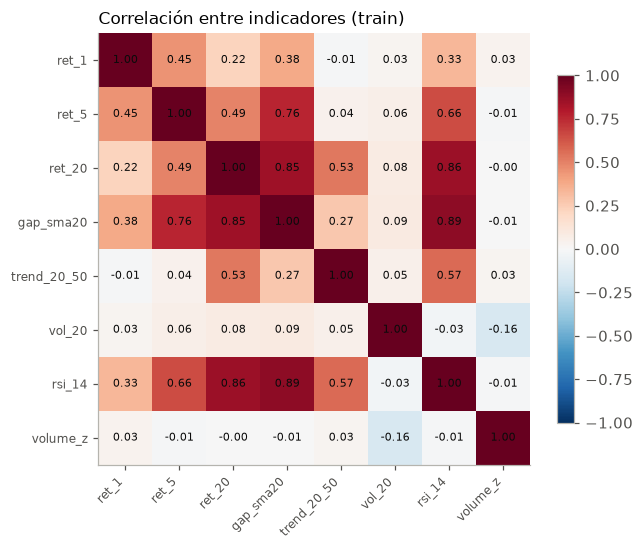

In [9]:
corr = train_z.corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color=INK)
fig.colorbar(im, shrink=0.8)
ax.set_title("Correlación entre indicadores (train)")
fig.tight_layout()

In [10]:
# ¿Predicen los indicadores el retorno del día siguiente? (train; correlación de Spearman)
nxt = ret.shift(-1).reindex(feats.index)
ic = feats.loc[:"2015"].corrwith(nxt.loc[:"2015"], method="spearman")
ic.round(3).to_frame("IC con el retorno de t+1")

,IC con el retorno de t+1
ret_1,0.030
ret_5,0.010
ret_20,0.004
gap_sma20,-0.007
trend_20_50,-0.018
vol_20,0.014
rsi_14,-0.010
volume_z,0.027


**Lectura.**
- En val, `vol_20` queda por debajo de su nivel de train (2016 fue un año más tranquilo): la
  distribución del estado **no es estacionaria**, un riesgo explícito para la generalización.
- `ret_20`, `gap_sma20`, `trend_20_50` y `rsi_14` están fuertemente correlacionados (todos miden
  momentum a distintos plazos); se mantienen porque la red puede combinarlos, pero aportan poca
  información independiente.
- La capacidad predictiva lineal de cada indicador sobre el retorno de mañana es casi nula
  (|IC| < 0,05). Es lo esperable en un activo líquido y anticipa que el agente difícilmente
  superará a comprar y mantener: el valor posible está más en gestionar el riesgo (volatilidad,
  caídas) que en predecir la dirección.

**Uso de la información futura.** Cada indicador en t usa solo ventanas que terminan en t; la
normalización usa media y desviación de train. `tests/test_invest_env.py` verifica ambas cosas
alterando los precios futuros y comprobando que los indicadores pasados no cambian.